# Math Symbol Classification - Data Exploration

Looking at the HASYv2 dataset before building the CNN model.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

labels_df = pd.read_csv('../data/hasy-data-labels.csv')
symbols_df = pd.read_csv('../data/symbols.csv')

print(f'Total images: {len(labels_df)}')
print(f'Total symbol classes: {len(symbols_df)}')
print(f'\nLabel columns: {list(labels_df.columns)}')
labels_df.head()

Total images: 168233
Total symbol classes: 369

Label columns: ['path', 'symbol_id', 'latex', 'user_id']


,path,symbol_id,latex,user_id
0,hasy-data/v2-00000.png,31,A,50
1,hasy-data/v2-00001.png,31,A,10
2,hasy-data/v2-00002.png,31,A,43
3,hasy-data/v2-00003.png,31,A,43
4,hasy-data/v2-00004.png,31,A,4435


369 classes is way too many for this project. I'll filter down to digits (0-9) and common math operators.

In [2]:
# the symbols I want to use
target_ids = {
    70: '0', 71: '1', 72: '2', 73: '3', 74: '4',
    75: '5', 76: '6', 77: '7', 78: '8', 79: '9',
    196: '+', 195: '-', 513: 'times', 526: 'div',
    184: 'dot', 524: 'pm', 918: '[', 919: ']'
}

filtered = labels_df[labels_df['symbol_id'].isin(target_ids.keys())].copy()
filtered['name'] = filtered['symbol_id'].map(target_ids)
print(f'Filtered to {len(filtered)} samples across {len(target_ids)} classes')

Filtered to 6530 samples across 18 classes


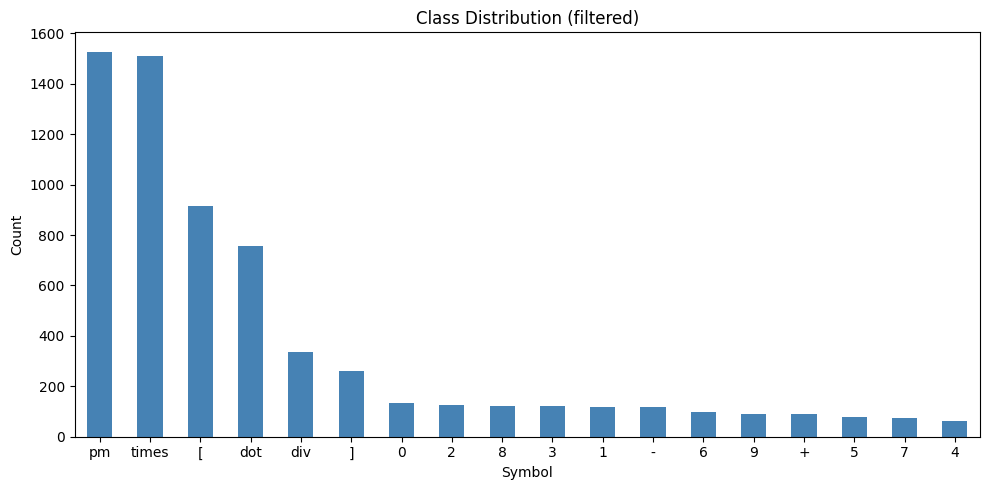

Min samples: 61 (4)
Max samples: 1528 (pm)


In [3]:
# class distribution
counts = filtered['name'].value_counts()
plt.figure(figsize=(10, 5))
counts.plot(kind='bar', color='steelblue')
plt.title('Class Distribution (filtered)')
plt.xlabel('Symbol')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(f'Min samples: {counts.min()} ({counts.idxmin()})')
print(f'Max samples: {counts.max()} ({counts.idxmax()})')

There's a significant class imbalance - digits have ~60-130 samples each while some operators like `times` and `pm` have over 1500. This could be an issue but I'll keep it simple for now and see how the model handles it.

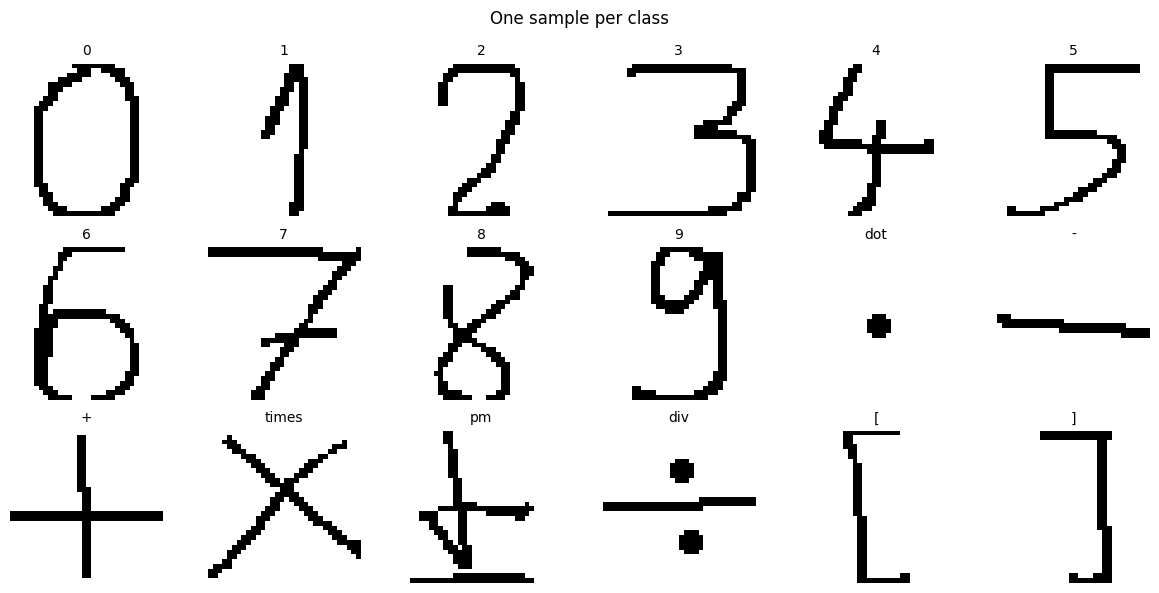

In [4]:
# show some sample images from each class
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
axes = axes.flatten()

for i, (sid, name) in enumerate(sorted(target_ids.items())):
    sample = filtered[filtered['symbol_id'] == sid].iloc[0]
    img = Image.open(os.path.join('..', 'data', sample['path']))
    axes[i].imshow(np.array(img), cmap='gray')
    axes[i].set_title(name, fontsize=10)
    axes[i].axis('off')

plt.suptitle('One sample per class', fontsize=12)
plt.tight_layout()
plt.show()

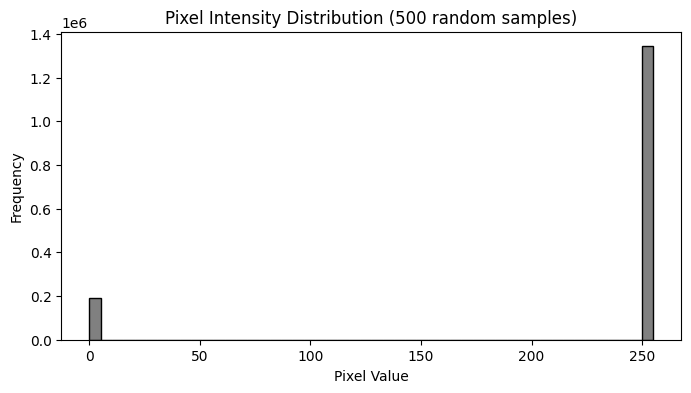

Most pixels are white (255) with symbol strokes in darker values.
Images are 32x32 grayscale.


In [5]:
# pixel intensity distribution
sample_imgs = []
for _, row in filtered.sample(500, random_state=42).iterrows():
    img = np.array(Image.open(os.path.join('..', 'data', row['path'])))
    sample_imgs.append(img)

all_pixels = np.concatenate([img.flatten() for img in sample_imgs])

plt.figure(figsize=(8, 4))
plt.hist(all_pixels, bins=50, color='gray', edgecolor='black')
plt.title('Pixel Intensity Distribution (500 random samples)')
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.show()

print(f'Most pixels are white (255) with symbol strokes in darker values.')
print(f'Images are 32x32 grayscale.')